# Experiment: XAUUSD ML Bull / ML Bear v0.3 (deep learning E3)

**คำถาม:** ถ้าเปลี่ยน E3 (การทดลองที่ v0.2 เลือก: feature 20 ตัว + uniqueness weights) จาก LightGBM เป็น **deep learning** จะทำนายได้ดีขึ้นไหม และชนะ always-long ได้ไหม

| | |
|---|---|
| **E3** | LightGBM pair (v0.2) — จุดเทียบ |
| **E6** | **MLP** บน feature 20 ตัวเดียวกับ E3 + weights |
| **E7** | **1D-CNN + GRU** อ่านแท่งย้อนหลัง 64 แท่ง (OHLC เทียบราคาปิดแท่งตัดสินใจ หน่วย ATR) + feature 20 ตัวของ E3 + weights |

- **Protocol เดิมของ v0.2 ทุกอย่าง:** expanding walk-forward รายเดือน เม.ย. 2025 → ม.ค. 2026, purge/embargo = time stop, calibrator + τ/m แบบ nested, label set `ct25`, กติกาเทรดของระบบ, ต้นทุน 0.30 USD/oz
- **การเทรน DL (ตั้งไว้ก่อนรัน):** median-impute + standardize fit บน train ของ fold เท่านั้น · early stopping บน 20% ท้ายของ train (purge แล้ว) · เฉลี่ย 3 seeds · GPU (RTX 3050) · ไม่ใช้ volume ใน sequence เพราะ tick volume ของ broker กับ volume ของ futures (feed ของ harness) เทียบกันไม่ได้
- **กฎเลือก (ประกาศก่อนรัน):** DL จะถูกเลือกแทน E3 ก็ต่อเมื่อ **AUC เฉลี่ยข้าม fold สูงกว่า E3** · เกณฑ์ความสำเร็จเหมือน v0.2: expectancy − always-long มีขอบล่าง CI 90% > 0
- **Aug–Sep 2026 (รอง):** holdout ช่วงนี้ **ถูกใช้ไปแล้วหนึ่งครั้งกับ v0.2** (`xau_holdout_aug_sep_2026.ipynb`) — ใช้ที่นี่เป็นหลักฐานรองเท่านั้น ไม่ใช้เลือกโมเดล

In [1]:
# Setup: imports and reproducibility
from __future__ import annotations

import dataclasses
import json
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybroker as pyb
import torch
from IPython.display import display
from sklearn.metrics import roc_auc_score

NB_DIR = Path.cwd()
assert (NB_DIR / "xau_ml").is_dir(), "เปิด notebook จาก Product/notebook/"
sys.path.insert(0, str(NB_DIR))
from xau_ml import config as C  # noqa: E402
from xau_ml import cv as CV  # noqa: E402
from xau_ml import data as D  # noqa: E402
from xau_ml import dl as DL  # noqa: E402
from xau_ml import features as F  # noqa: E402
from xau_ml import holdout as H  # noqa: E402
from xau_ml import labels as L  # noqa: E402
from xau_ml import pb as P  # noqa: E402
from xau_ml import sim as S  # noqa: E402
from xau_ml import v2 as V  # noqa: E402
from xau_ml.model import Calibrator  # noqa: E402

SEED = 42
np.random.seed(SEED)
pyb.disable_progress_bar()
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.4f}".format)
SIDES = ("bull", "bear")
LS = C.LABEL_SETS["ct25"]
E3 = next(e for e in V.EXPERIMENTS if e.id == "E3")
MODEL_DIR_V3 = C.MODEL_DIR / "v3_dl"
print(f"torch {torch.__version__} | device {DL.DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'}) | seeds {DL.N_SEEDS}")

torch 2.6.0+cu124 | device cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU) | seeds 3


## 1. ข้อมูล, feature, label และ input แบบ sequence

ข้อมูลและ feature ชุดเดียวกับ v0.2 (ผลตรวจ look-ahead ของ feature อยู่ใน v0.1/v0.2) · input ใหม่คือ sequence 64 แท่งต่อแถว — ตรวจด้วย **truncation test** ว่า sequence ของแถว t สร้างจากแท่ง ≤ t เท่านั้น

In [2]:
RAW = {tf: D.load(tf, C.WARMUP_START[tf]) for tf in ("15m", "1h", "1d")}
FR, COLS, SEQ = {}, {}, {}
for hz in C.HORIZONS.values():
    fr = L.add_labels(F.build(RAW[hz.tf], hz.tf, {tf: RAW[tf] for tf in hz.htf}), hz, LS)
    FR[hz.name], COLS[hz.name] = fr, V.columns(E3, F.feature_columns(fr))
    SEQ[hz.name] = DL.sequences(fr)
    # causality: the sequence of row t built from bars <= t only equals the full-data one
    rng = np.random.default_rng(SEED)
    for t in rng.choice(np.flatnonzero(fr["date"] >= C.TRAIN[0]), 30, replace=False):
        again = DL.sequences(fr.iloc[: t + 1])[-1]
        assert np.allclose(again, SEQ[hz.name][t], equal_nan=True)
    print(f"{hz.name}: {len(COLS[hz.name])} tabular features + sequence {SEQ[hz.name].shape[1:]} | "
          f"usable rows {int(CV.usable(fr[fr['date'] >= C.TRAIN[0]]).sum()):,} | sequence truncation test ✓")
print(COLS["intraday"])

intraday: 20 tabular features + sequence (64, 4) | usable rows 22,328 | sequence truncation test ✓


swing: 20 tabular features + sequence (64, 4) | usable rows 5,263 | sequence truncation test ✓
['atr_pct', 'atr_regime', 'rv_32', 'bb_width', 'adx14', 'hour', 'dow', 'd1_rsi14', 'd1_adx14', 'd1_di_diff', 'd1_dist_sma50_atr', 'd1_dist_sma200_atr', 'd1_macd_hist_atr', 'd1_ret_atr_5', 'd1_range_pos_20', 'd1_atr_pct', 'd1_above_sma50', 'd1_above_sma200', 'd1_trend', 'd1_prev_range_pos']


In [3]:
FOLDS = {}
for hz in C.HORIZONS.values():
    FOLDS[hz.name] = CV.monthly_folds(FR[hz.name], hz, C.WF2_FIRST_FOLD, C.WF2_LAST_FOLD, C.TRAIN[0])
    CV.assert_folds(FR[hz.name], FOLDS[hz.name], hz)
print({k: [f.name for f in v] for k, v in FOLDS.items()})

{'intraday': ['2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12', '2026-01'], 'swing': ['2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12', '2026-01']}


## 2. Walk-forward: E3 (LightGBM) vs E6 (MLP) vs E7 (CNN+GRU)

In [4]:
OOF, FOLD_ML, rows = {}, {}, []
for hz in C.HORIZONS.values():
    fr, cols, folds = FR[hz.name], COLS[hz.name], FOLDS[hz.name]
    t0 = time.time()
    OOF[(hz.name, "E3")], FOLD_ML[(hz.name, "E3")] = V.run_oof(E3, fr, folds, cols, hz)
    secs = {"E3": time.time() - t0}
    for exp in DL.DL_EXPERIMENTS:
        t0 = time.time()
        OOF[(hz.name, exp.id)], FOLD_ML[(hz.name, exp.id)] = DL.run_oof_dl(exp, fr, folds, cols, hz, SEQ[hz.name])
        secs[exp.id] = time.time() - t0
    for eid in ("E3", *[e.id for e in DL.DL_EXPERIMENTS]):
        pf = FOLD_ML[(hz.name, eid)]
        rows.append({"horizon": hz.name, "exp": eid, "auc_bull": pf["auc_bull"].mean(), "auc_bear": pf["auc_bear"].mean(),
                     "auc_mean": pf[["auc_bull", "auc_bear"]].mean(axis=1).mean(),
                     "auc_bull_min_fold": pf["auc_bull"].min(), "auc_bear_min_fold": pf["auc_bear"].min(),
                     "logloss_gain_bull": (pf["logloss_clim_bull"] - pf["logloss_bull"]).mean(),
                     "logloss_gain_bear": (pf["logloss_clim_bear"] - pf["logloss_bear"]).mean(),
                     "train_seconds": round(secs[eid], 1)})
ML_TABLE = pd.DataFrame(rows)
display(ML_TABLE)
display(pd.concat({f"{h}/{e}": FOLD_ML[(h, e)].set_index("fold")[["auc_bull", "auc_bear"]] for (h, e) in FOLD_ML}, axis=1).round(3))

,horizon,exp,auc_bull,auc_bear,auc_mean,auc_bull_min_fold,auc_bear_min_fold,logloss_gain_bull,logloss_gain_bear,train_seconds
0,intraday,E3,0.5725,0.6170,0.5948,0.4885,0.5791,0.0049,0.0040,5.4000
1,intraday,E6,0.5462,0.5878,0.5670,0.4742,0.5169,-0.0008,0.0039,30.3000
2,intraday,E7,0.5418,0.5852,0.5635,0.4908,0.4685,-0.0007,0.0049,63.1000
3,swing,E3,0.5715,0.5977,0.5846,0.3499,0.2264,-0.0142,-0.0616,3.1000
4,swing,E6,0.5100,0.4582,0.4841,0.2924,0.2162,-0.0180,-0.0123,8.5000
5,swing,E7,0.4959,0.4809,0.4884,0.2681,0.1385,-0.0186,-0.0086,20.4000


intraday/E3          intraday/E6          intraday/E7          swing/E3          swing/E6          swing/E7         
           auc_bull auc_bear    auc_bull auc_bear    auc_bull auc_bear auc_bull auc_bear auc_bull auc_bear auc_bull auc_bear
fold                                                                                                                        
2025-04      0.4880   0.6590      0.5220   0.5380      0.5520   0.5150   0.5570   0.7380   0.5480   0.3780   0.4910   0.4790
2025-05      0.5220   0.6320      0.5330   0.5170      0.5350   0.4680   0.5650   0.5760   0.5230   0.5710   0.5720   0.5290
2025-06      0.6160   0.5790      0.5170   0.5700      0.4920   0.5630   0.7190   0.6240   0.6000   0.3490   0.5760   0.4040
2025-07      0.6100   0.6590      0.5630   0.6010      0.5320   0.6030   0.5720   0.4090   0.5460   0.4660   0.5590   0.5230
2025-08      0.5580   0.5800      0.5330   0.6770      0.5310   0.6620   0.5410   0.5790   0.4060   0.6060   0.4970   0.6540
2025-09      0.6730   0.5880      0.6160   0.6120      0.6000   0.6670   0.6690   0.2260   0.5120   0.4490   0.4000   0.4040
2025-10      0.6070   0.5920      0.5820   0.5450      0.5520   0.5660   0.3500   0.8220   0.5160   0.2970   0.4570   0.2910
2025-11      0.5610   0.5950      0.5220   0.6360      0.5320   0.6440   0.6530   0.8920   0.6470   0.7060   0.6280   0.7900
2025-12      0.5920   0.5960      0.6000   0.5260      0.6010   0.5270   0.6550   0.6680   0.5100   0.5450   0.5100   0.5960
2026-01      0.4980   0.6890      0.4740   0.6550      0.4910   0.6380   0.4330   0.4430   0.2920   0.2160   0.2680   0.1390

**อ่านผล:** E3 (LightGBM) ชนะทุกช่อง; swing DL ต่ำกว่า 0.5 · ตารางรายเดือนแสดงว่า DL ไม่ได้ดีกว่าแม้แต่เดือนเดียวอย่างสม่ำเสมอ

In [5]:
# Nested OOS trading (Jun 2025 - Jan 2026) + baselines on the same rows + bootstrap vs always-long
TRADE, TRADES, NEST = [], {}, {}
for hz in C.HORIZONS.values():
    fr, names = FR[hz.name], [f.name for f in FOLDS[hz.name]]
    for eid in ("E3", *[e.id for e in DL.DL_EXPERIMENTS]):
        trades, log, cal, sig, scored = V.nested_trading(fr, OOF[(hz.name, eid)], names, C.WF2_BURN_IN, C.MIN_VAL_TRADES[hz.tf])
        TRADES[(hz.name, eid)], NEST[(hz.name, eid)] = trades, (log, cal, sig, scored)
        TRADE.append({"horizon": hz.name, "strategy": eid, **S.metrics(trades)})
    o = OOF[(hz.name, "E3")]
    scored_pos = o["pos"].to_numpy()[o["fold"].isin(names[C.WF2_BURN_IN:]).to_numpy()]
    for kind in ("always_long", "always_short", "sma20_50_cross"):
        TRADES[(hz.name, kind)] = V.baseline_trades(fr, scored_pos, kind)
        TRADE.append({"horizon": hz.name, "strategy": kind, **S.metrics(TRADES[(hz.name, kind)])})
TRADE = pd.DataFrame(TRADE)
for i, r in TRADE.iterrows():
    t = TRADES[(r["horizon"], r["strategy"])]["r"].to_numpy()
    base = TRADES[(r["horizon"], "always_long")]["r"].to_numpy()
    TRADE.loc[i, ["exp_ci90_lo", "exp_ci90_hi"]] = CV.bootstrap_mean_ci(t) if len(t) else (np.nan, np.nan)
    TRADE.loc[i, ["vs_long_ci90_lo", "vs_long_ci90_hi"]] = CV.bootstrap_diff_ci(t, base) if len(t) else (np.nan, np.nan)
TRADE["beats_always_long"] = TRADE["vs_long_ci90_lo"] > 0
display(TRADE[["horizon", "strategy", "trades", "win_rate", "profit_factor", "expectancy_r", "exp_ci90_lo", "exp_ci90_hi",
               "vs_long_ci90_lo", "vs_long_ci90_hi", "beats_always_long", "max_dd_pct", "long_share"]])

,horizon,strategy,trades,win_rate,profit_factor,expectancy_r,exp_ci90_lo,exp_ci90_hi,vs_long_ci90_lo,vs_long_ci90_hi,beats_always_long,max_dd_pct,long_share
0,intraday,E3,79,0.4810,1.0772,0.0383,-0.1573,0.2494,-0.1539,0.2637,False,13.6085,0.8481
1,intraday,E6,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,0.0000,NaN
2,intraday,E7,262,0.3855,0.7946,-0.1258,-0.2386,-0.0087,-0.2391,0.0101,False,39.8009,1.0000
3,intraday,always_long,1608,0.4335,0.9841,-0.0088,-0.0580,0.0384,-0.0680,0.0679,False,53.3379,1.0000
4,intraday,always_short,1374,0.3603,0.8512,-0.0918,-0.1483,-0.0346,-0.1577,-0.0089,False,78.9322,0.0000
5,intraday,sma20_50_cross,262,0.4351,1.1539,0.0836,-0.0485,0.2189,-0.0471,0.2354,False,14.5565,0.4885
6,swing,E3,134,0.4925,1.4681,0.2284,0.0610,0.4010,-0.1925,0.2716,False,11.2052,1.0000
7,swing,E6,124,0.4919,1.4031,0.1999,0.0180,0.3857,-0.2274,0.2501,False,7.4518,1.0000
8,swing,E7,103,0.4951,1.4573,0.2234,0.0289,0.4316,-0.2161,0.2993,False,7.9771,1.0000
9,swing,always_long,158,0.4810,1.3759,0.1893,0.0262,0.3497,-0.2354,0.2256,False,11.2052,1.0000


**อ่านผล:** MLP ของ intraday ไม่มีชุด τ/m ไหนผ่านเกณฑ์จึงไม่เทรด; CNN+GRU intraday ขาดทุนอย่างมีนัยสำคัญ (CI ทั้งช่วง < 0); swing ทุกตัว ≈ always-long

## 3. เลือกตามกฎที่ประกาศไว้ + รายละเอียด

intraday: E3 0.5948 | E6 0.5670 | E7 0.5635 → best DL E6; chosen by the rule: E3
swing: E3 0.5846 | E6 0.4841 | E7 0.4884 → best DL E7; chosen by the rule: E3


,horizon,strategy,period,trades,win_rate,profit_factor,expectancy_r,long_share
0,intraday,E3,never seen 2025-06..09,32,0.3125,0.3758,-0.3927,0.6250
1,intraday,E3,seen in v0.1 2025-10..2026-01,47,0.5957,1.8202,0.3317,1.0000
2,intraday,E6,never seen 2025-06..09,0,NaN,NaN,NaN,NaN
3,intraday,E6,seen in v0.1 2025-10..2026-01,0,NaN,NaN,NaN,NaN
4,intraday,always_long,never seen 2025-06..09,895,0.4190,0.9338,-0.0376,1.0000
5,intraday,always_long,seen in v0.1 2025-10..2026-01,713,0.4516,1.0515,0.0274,1.0000
6,swing,E3,never seen 2025-06..09,66,0.4697,1.3360,0.1751,1.0000
7,swing,E3,seen in v0.1 2025-10..2026-01,68,0.5147,1.6146,0.2801,1.0000
8,swing,E7,never seen 2025-06..09,37,0.4865,1.3590,0.1876,1.0000
9,swing,E7,seen in v0.1 2025-10..2026-01,66,0.5000,1.5185,0.2435,1.0000


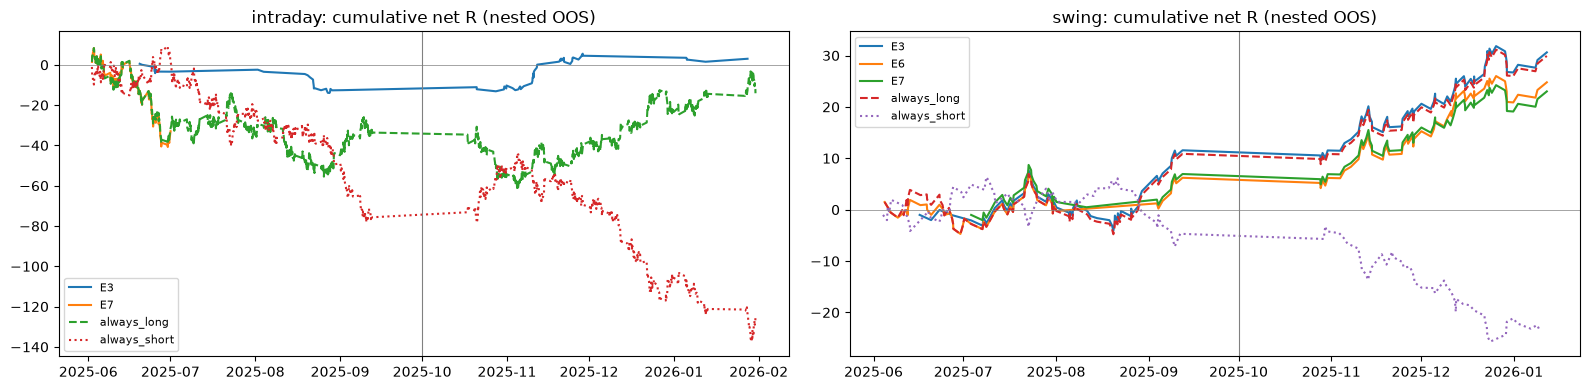

In [6]:
CHOSEN, BEST_DL = {}, {}
for hz in C.HORIZONS.values():
    t = ML_TABLE[ML_TABLE["horizon"] == hz.name].set_index("exp")["auc_mean"]
    best_dl = max((e for e in DL.DL_EXPERIMENTS), key=lambda e: t[e.id])
    BEST_DL[hz.name] = best_dl
    CHOSEN[hz.name] = best_dl.id if t[best_dl.id] > t["E3"] else "E3"
    print(f"{hz.name}: E3 {t['E3']:.4f} | E6 {t['E6']:.4f} | E7 {t['E7']:.4f} → best DL {best_dl.id}; chosen by the rule: {CHOSEN[hz.name]}")

rows = []
for hzn in CHOSEN:
    for eid in ("E3", BEST_DL[hzn].id, "always_long"):
        t = TRADES[(hzn, eid)]
        for part, m in (("never seen 2025-06..09", pd.to_datetime(t["entry"]) < C.SEEN_FROM),
                        ("seen in v0.1 2025-10..2026-01", pd.to_datetime(t["entry"]) >= C.SEEN_FROM)):
            sub = t[m.to_numpy()]
            rows.append({"horizon": hzn, "strategy": eid, "period": part,
                         **S.metrics(sub.assign(equity=np.cumprod(1 + C.RISK_PCT * sub["r"].to_numpy())))})
display(pd.DataFrame(rows)[["horizon", "strategy", "period", "trades", "win_rate", "profit_factor", "expectancy_r", "long_share"]])

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, hzn in zip(axes, CHOSEN):
    for name, style in (("E3", "-"), ("E6", "-"), ("E7", "-"), ("always_long", "--"), ("always_short", ":")):
        t = TRADES[(hzn, name)]
        if len(t):
            ax.plot(pd.to_datetime(t["exit"]), t["r"].cumsum(), style, label=name)
    ax.axvline(pd.Timestamp(C.SEEN_FROM), color="grey", lw=0.8)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"{hzn}: cumulative net R (nested OOS)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**อ่านผล:** กฎที่ประกาศไว้เลือก E3 (LightGBM) ทั้งสอง horizon — DL ไม่ชนะ

## 4. Backtest ใน pybroker (สัญญาณ nested ของ DL ที่ดีที่สุด + E3)

In [7]:
INDS = P.register_indicators()
SMA_INDS = P.sma_indicators()
ALL_CUSTOM = sorted({c for cols in COLS.values() for c in cols if c.startswith(("h1_", "d1_"))} | {"no_entry", "ml_signal"}
                    | {c for fr in FR.values() for c in fr.columns if c.startswith(("h1_", "d1_")) and not c.endswith("t_close")})


def use_columns(cols):
    for c in ALL_CUSTOM:
        try:
            pyb.unregister_columns(c)
        except Exception:  # noqa: BLE001
            pass
    pyb.register_columns(*cols)


PB = []
for hzn in CHOSEN:
    hz = C.HORIZONS[hzn]
    htf = [c for c in F.feature_columns(FR[hzn]) if c.startswith(("h1_", "d1_"))]
    for eid in ("E3", BEST_DL[hzn].id):
        fr = FR[hzn].copy()
        log, cal, sig, scored = NEST[(hzn, eid)]
        pos = OOF[(hzn, eid)]["pos"].to_numpy()
        fr["ml_signal"] = 0.0
        fr.loc[fr.index[pos[scored]], "ml_signal"] = sig[scored].astype(float)
        use_columns([*htf, "no_entry", "ml_signal"])
        start, end = fr["date"].iloc[pos[scored].min()], fr["date"].iloc[pos[scored].max()]
        st = pyb.Strategy(P.pb_frame(fr, htf, extra=("ml_signal",)), C.WARMUP_START[hz.tf], end, P.config(hz.tf))
        st.add_execution(P.signal_exec(hz, LS), [C.SYMBOL], indicators=INDS + SMA_INDS)
        res = st.backtest(start_date=start, end_date=end, timeframe=hz.tf)
        PB.append({"horizon": hzn, "strategy": eid, "engine": "pybroker", **P.r_metrics(P.trades_in_r(res, fr), res)})
        PB.append({"horizon": hzn, "strategy": eid, "engine": "replica", **S.metrics(TRADES[(hzn, eid)])})
PB = pd.DataFrame(PB)
display(PB[["horizon", "strategy", "engine", "trades", "win_rate", "profit_factor", "expectancy_r", "total_r", "max_dd_pct", "return_pct", "long_share"]])

Backtesting: 2025-06-02 05:00:00 to 2026-01-30 19:30:00



Computing indicators...


Test split: 2025-06-02 05:00:00 to 2026-01-30 19:30:00


Finished backtest: 0:00:01


Backtesting: 2025-06-02 05:00:00 to 2026-01-30 19:30:00



...

Backtesting: 2025-06-04 03:00:00 to 2026-01-09 11:00:00



Computing indicators...


Test split: 2025-06-04 03:00:00 to 2026-01-09 11:00:00


Finished backtest: 0:00:00


,horizon,strategy,engine,trades,win_rate,profit_factor,expectancy_r,total_r,max_dd_pct,return_pct,long_share
0,intraday,E3,pybroker,79,0.4810,1.0791,0.0391,3.0906,13.7229,2.6454,0.8481
1,intraday,E3,replica,79,0.4810,1.0772,0.0383,3.0221,13.6085,NaN,0.8481
2,intraday,E6,pybroker,0,NaN,NaN,NaN,NaN,0.0000,0.0000,NaN
3,intraday,E6,replica,0,NaN,NaN,NaN,0.0000,0.0000,NaN,NaN
4,swing,E3,pybroker,134,0.5000,1.4955,0.2382,31.9185,11.4261,36.1195,1.0000
5,swing,E3,replica,134,0.4925,1.4681,0.2284,30.6085,11.2052,NaN,1.0000
6,swing,E7,pybroker,101,0.4950,1.4562,0.2229,22.5081,8.1798,24.2064,1.0000
7,swing,E7,replica,103,0.4951,1.4573,0.2234,23.0126,7.9771,NaN,1.0000


## 5. โมเดล DL สุดท้าย + บันทึก

fit DL ตัวที่ดีที่สุดของแต่ละ horizon บนทุกแถวที่ใช้ได้ (2025-01-02 → 2026-01-30) · Platt calibrator บน out-of-fold · τ/m บน out-of-fold ช่วงที่นับผล · บันทึกที่ `models/v3_dl/` (state_dict ต่อ seed + JSON ของ scaler/สถาปัตยกรรม/calibrator/τ-m) พร้อม flag ว่าชนะ E3 ตามกฎหรือไม่

In [8]:
FINAL = {}
for hzn, exp in BEST_DL.items():
    hz, fr = C.HORIZONS[hzn], FR[hzn]
    rows_all = np.flatnonzero(CV.usable(fr) & (fr["date"] >= C.TRAIN[0]).to_numpy())
    fitted = DL.fit_dl(exp, fr, rows_all, COLS[hzn], hz, SEQ[hzn])
    oof = OOF[(hzn, exp.id)]
    cals = {s: Calibrator.fit("platt", oof[f"p_{s}_raw"].to_numpy(), fr[f"y_{s}"].to_numpy()[oof["pos"]]) for s in SIDES}
    log, cal, sig, scored = NEST[(hzn, exp.id)]
    sc = oof[scored]
    _, best = S.select_tau_m(fr, sc["pos"].to_numpy(), cals["bull"](sc["p_bull_raw"].to_numpy()), cals["bear"](sc["p_bear_raw"].to_numpy()),
                             C.TAU_GRID, C.MARGIN_GRID, C.MIN_VAL_TRADES[hz.tf])
    rule = {"tau": best["tau"], "m": best["m"], "no_trade": False} if best else {"tau": 1.01, "m": 0.0, "no_trade": True}
    FINAL[hzn] = (fitted, cals, rule)
    meta = {"version": "xau-bullbear-0.3.0-dl", "symbol": C.SYMBOL, "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "horizon": hzn, "timeframe": hz.tf, "context_timeframes": list(hz.htf), "experiment": {"id": exp.id, "name": exp.name},
            "selected_over_lightgbm_E3": CHOSEN[hzn] == exp.id, "features": COLS[hzn],
            "label": {"set": LS.name, "tp_r": LS.tp_r, "counter_trend_tp_r": LS.ct_tp_r, "time_stop_bars": hz.time_stop, "intrabar_rule": "stop_first"},
            "training": {"rows": len(rows_all), "from": str(fr["date"].iloc[rows_all].min()), "to": str(fr["date"].iloc[rows_all].max()),
                         "epochs_per_seed": fitted.epochs, "device": str(DL.DEVICE)},
            "calibrators": {s: c.to_json() for s, c in cals.items()}, "signal_rule": rule,
            "metrics": {"walkforward_ml": ML_TABLE.query("horizon == @hzn").drop(columns="horizon").to_dict("records"),
                        "walkforward_trading": TRADE.query("horizon == @hzn").drop(columns="horizon").to_dict("records")}}
    DL.save(MODEL_DIR_V3, f"xau_{hzn}_{LS.name}_{exp.id}", fitted, meta)
    # reload check: state_dicts (weights only) → identical predictions
    nets = []
    for i in range(len(fitted.nets)):
        net = (DL.MLP if exp.kind == "mlp" else DL.SeqNet)(len(COLS[hzn]), exp.cfg).to(DL.DEVICE)
        net.load_state_dict(torch.load(MODEL_DIR_V3 / f"xau_{hzn}_{LS.name}_{exp.id}.seed{i}.pt", weights_only=True))
        nets.append(net)
    re = DL.FittedDL(exp, COLS[hzn], fitted.scaler, nets, fitted.epochs).predict(fr, rows_all[-500:], SEQ[hzn])
    ref = fitted.predict(fr, rows_all[-500:], SEQ[hzn])
    assert all(np.allclose(re[s], ref[s], atol=1e-6) for s in SIDES)
    print(f"{hzn}: saved {exp.id} (epochs {fitted.epochs}), rule {rule}, selected over E3: {CHOSEN[hzn] == exp.id} — reload ✓")

intraday: saved E6 (epochs [1, 1, 1]), rule {'tau': 0.325, 'm': 0.2, 'no_trade': False}, selected over E3: False — reload ✓


swing: saved E7 (epochs [3, 3, 6]), rule {'tau': 0.325, 'm': 0.0, 'no_trade': False}, selected over E3: False — reload ✓


**อ่านผล:** early stopping หยุดที่ epoch 1–6 — โมเดลเริ่ม overfit แทบทันที เป็นสัญญาณว่าข้อมูล/สัญญาณไม่พอสำหรับ neural net

## 6. หลักฐานรอง: Aug–Sep 2026 (holdout ที่ใช้ไปแล้วครั้งหนึ่งกับ v0.2)

ข้อมูลจาก `GC=F` (yfinance) แปลงเป็นเวลา server เดียวกับข้อมูลเทรน (`xau_ml/holdout.py`) — 15m ย้อนหลังได้ ~60 วัน · เทียบ DL ที่ดีที่สุด กับ E3/LightGBM (`models/v2`) และ baseline บนแถวเดียวกัน · **ไม่ใช้เลือกหรือปรับอะไร**

In [9]:
try:
    HB = H.load_bars()
    HOLD = []
    for hzn, (fitted, cals, rule) in FINAL.items():
        hz = C.HORIZONS[hzn]
        frh = L.add_labels(F.build(HB[hz.tf], hz.tf, {tf: HB[tf] for tf in hz.htf}), hz, LS)
        rows_h = H.holdout_rows(frh)
        if len(rows_h) == 0:
            print(f"{hzn}: no holdout rows (data not available)")
            continue
        p = fitted.predict(frh, rows_h, DL.sequences(frh))
        sig = S.signals(cals["bull"](p["bull"]), cals["bear"](p["bear"]), rule["tau"], rule["m"])
        res = {f"{BEST_DL[hzn].id} (DL)": S.run(frh, rows_h, sig)}
        _, fr_e3 = H.frame(C.MODEL_DIR_V2 / f"xau_{hzn}_{LS.name}.json", HB)
        res["E3 (LightGBM v0.2)"] = S.run(fr_e3, H.holdout_rows(fr_e3), fr_e3["signal"].to_numpy()[H.holdout_rows(fr_e3)])
        for kind in ("always_long", "always_short", "sma_cross"):
            res[kind] = V.baseline_trades(frh, rows_h, kind)
        y = {s: frh[f"y_{s}"].to_numpy()[rows_h] for s in SIDES}
        for name, t in res.items():
            HOLD.append({"horizon": hzn, "strategy": name, "rows": len(rows_h), "from": frh["date"].iloc[rows_h].min(), **S.metrics(t)})
        print(f"{hzn}: DL holdout AUC bull {roc_auc_score(y['bull'], p['bull']):.3f} | bear {roc_auc_score(y['bear'], p['bear']):.3f}")
    HOLD = pd.DataFrame(HOLD)
    display(HOLD[["horizon", "strategy", "rows", "from", "trades", "win_rate", "profit_factor", "expectancy_r", "total_r", "max_dd_pct", "long_share"]])
except Exception as e:  # noqa: BLE001 — network-dependent; the walk-forward above is the primary result
    print("holdout unavailable:", type(e).__name__, str(e)[:200])

intraday: DL holdout AUC bull 0.527 | bear 0.557


swing: DL holdout AUC bull 0.490 | bear 0.546


,horizon,strategy,rows,from,trades,win_rate,profit_factor,expectancy_r,total_r,max_dd_pct,long_share
0,intraday,E6 (DL),3843,2026-08-03 01:00:00,0,NaN,NaN,NaN,0.0000,0.0000,NaN
1,intraday,E3 (LightGBM v0.2),3843,2026-08-03 01:00:00,90,0.4778,1.3131,0.1623,14.6064,7.8684,1.0000
2,intraday,always_long,3843,2026-08-03 01:00:00,476,0.4055,0.9474,-0.0296,-14.0852,37.4622,1.0000
3,intraday,always_short,3843,2026-08-03 01:00:00,484,0.4132,0.9302,-0.0396,-19.1569,37.4705,0.0000
4,intraday,sma_cross,3843,2026-08-03 01:00:00,76,0.4342,1.0814,0.0450,3.4187,9.3167,0.5000
5,swing,E7 (DL),960,2026-08-03 01:00:00,61,0.3607,0.9158,-0.0536,-3.2674,15.4313,1.0000
6,swing,E3 (LightGBM v0.2),960,2026-08-03 01:00:00,60,0.3667,0.9402,-0.0376,-2.2588,14.7107,1.0000
7,swing,always_long,960,2026-08-03 01:00:00,61,0.3607,0.9158,-0.0536,-3.2674,15.4313,1.0000
8,swing,always_short,960,2026-08-03 01:00:00,64,0.3594,0.9031,-0.0626,-4.0045,12.9509,0.0000
9,swing,sma_cross,960,2026-08-03 01:00:00,16,0.3750,1.1483,0.0884,1.4141,5.3776,0.5625


**อ่านผล:** บน Aug–Sep 2026 E3 LightGBM intraday ดีที่สุด (PF 1.31, +0.16R) ขณะที่ DL intraday ไม่เทรด และ swing ทุกตัวขาดทุนพอๆ กับ always-long

## Results (รายงาน v0.3 — deep learning)

> **ผู้อ่าน:** ทีม harness · **วันที่:** 2026-10-04 · **สถานะ:** research — ยังไม่ต่อ backend

### บทสรุป
- **Deep learning แพ้ LightGBM (E3) ทุกตัว ทุก horizon** → ตามกฎที่ประกาศไว้ **คงใช้ E3 (LightGBM)** ทั้ง intraday และ swing
- สาเหตุหลัก: ข้อมูลน้อยและสัญญาณอ่อน — DL หยุดเทรนที่ epoch 1–6 (early stopping) แปลว่าเริ่ม overfit แทบทันทีที่เรียนรู้อะไรได้; sequence 64 แท่ง (E7) ไม่ได้ให้ข้อมูลเพิ่มจาก feature 20 ตัว
- เกณฑ์ "ชนะ always-long อย่างมีนัยสำคัญ" — **ไม่ผ่าน** เหมือน v0.2

### ผล ML (walk-forward 10 เดือน, AUC เฉลี่ย)

| | intraday bull | intraday bear | swing bull | swing bear | เวลาเทรน |
|---|---|---|---|---|---|
| **E3 LightGBM** | **0.573** | **0.617** | **0.572** | **0.598** | 3–5 วินาที |
| E6 MLP | 0.546 | 0.588 | 0.510 | 0.458 | 9–30 วินาที |
| E7 CNN + GRU | 0.542 | 0.585 | 0.496 | 0.481 | 20–63 วินาที (GPU) |

swing DL ต่ำกว่า 0.5 (แย่กว่าสุ่ม) — swing มีแถวเทรนแค่ 1.4k–5k แถวต่อ fold ซึ่งน้อยเกินไปสำหรับ neural net

### ผลเทรด out-of-sample แบบ nested (มิ.ย. 2025 → ม.ค. 2026)

| | trades | win rate | PF | expectancy (CI 90%) | long |
|---|---|---|---|---|---|
| intraday E3 | 79 | 48.1% | 1.08 | +0.04R (−0.16 … +0.25) | 85% |
| intraday E6 MLP | 0 | – | – | ไม่มีชุด τ/m ไหนผ่านเกณฑ์ | – |
| intraday E7 CNN+GRU | 262 | 38.6% | 0.79 | **−0.13R (−0.24 … −0.01)** ขาดทุนอย่างมีนัยสำคัญ | 100% |
| swing E3 | 134 | 49.3% | 1.47 | +0.23R (+0.06 … +0.40) | 100% |
| swing E7 CNN+GRU | 103 | 49.5% | 1.46 | +0.22R (+0.03 … +0.43) | 100% |
| swing always-long | 158 | 48.1% | 1.38 | +0.19R (+0.03 … +0.35) | 100% |

swing ทุกตัวที่ "กำไร" คือ long 100% — ได้ผลจากตลาดขาขึ้น ไม่ใช่จากโมเดล · pybroker ยืนยันตัวเลขของ replica (ต่างกัน ≤ 2 เทรด)

### หลักฐานรอง Aug–Sep 2026 (holdout ที่ถูกใช้แล้วหนึ่งครั้งกับ v0.2)

| | intraday trades | intraday PF | intraday expectancy | swing trades | swing PF | swing expectancy |
|---|---|---|---|---|---|---|
| DL (E6 / E7) | 0 | – | – | 61 | 0.92 | −0.05R |
| **E3 LightGBM v0.2** | 90 | **1.31** | **+0.16R** | 60 | 0.94 | −0.04R |
| always-long | 476 | 0.95 | −0.03R | 61 | 0.92 | −0.05R |
| always-short | 484 | 0.93 | −0.04R | 64 | 0.90 | −0.06R |
| SMA20/50 | 76 | 1.08 | +0.05R | 16 | 1.15 | +0.09R |

- DL บน holdout: AUC intraday 0.53/0.56, swing 0.49/0.55 — ต่ำกว่า E3 เช่นกัน
- **intraday E3 ดีที่สุดบน Aug–Sep** (win rate 47.8%, PF 1.31) ในช่วงที่ always-long ขาดทุน — สอดคล้องกับเป้า 40–50% / PF > 1 แต่ 90 เทรดยังน้อย และ holdout นี้ถูกดูไปแล้วครั้งหนึ่ง
- swing: E7 = always-long ทุกตัวเลข (long ทุกแท่ง)

### ข้อสรุปและข้อเสนอ
- ❌ **ไม่ใช้ deep learning** กับโจทย์นี้ในตอนนี้ — แพ้ทั้งความแม่น ความเร็ว และความง่ายในการต่อเข้า backend (LightGBM โหลดเป็น text file ได้เลย)
- ✅ ใช้ **E3 LightGBM (`models/v2/`)** ต่อ — โดยเฉพาะ **intraday**: P_bear เป็นตัวที่เสถียรที่สุด (AUC 0.62) และเป็นตัวเดียวที่ทำกำไรบน Aug–Sep
- DL จะคุ้มเมื่อมีข้อมูลมากขึ้นหลายเท่า (หลายปี/หลาย symbol) หรือ input ที่ feature ทำไม่ได้ (order book, ข่าว) — ซึ่งขัดกับเงื่อนไข "ใช้แค่ regime 2025+"
- โมเดล DL ที่บันทึกไว้ (`models/v3_dl/`, `selected_over_lightgbm_E3: false`) เก็บไว้เพื่อ reproduce เท่านั้น

## Next steps

1. **intraday E3 + P_bear** เป็นตัวเลือกหลักสำหรับต่อเข้า harness ในฐานะ "หลักฐานให้ analyst" (deterministic predictor, F1)
2. หา window ใหม่ที่ไม่เคยดู (ต.ค. 2026 เป็นต้นไป) เพื่อยืนยัน E3 intraday — Aug–Sep ถูกดูไปแล้ว
3. ถ้าจะลอง DL อีก: ต้องมีข้อมูลมากกว่านี้มาก — ทางเลือกคือ pretrain บนหลายปี/หลาย symbol (ATR-normalized) แล้ว fine-tune บน 2025+ ซึ่งต้องให้คุณตัดสินเรื่อง regime ก่อน